# 01. Exploratory data analysis

**Question.** What does the data look like before any test is run? How much is traded on each team, how does one game's price move in the 30 hours before tipoff, and how are the tipoff prices spread between 0 and 1?

**Plan.** This notebook follows `ANALYSIS_PLAN.md` section 4 (the popularity measure, shown here only as a ranking) and section 6 (EDA outputs). Everything here is descriptive. No game outcome is used.

**Data.** `data/processed/snapshots.csv`, main sample, and `data/processed/example_price_path.csv` for the example price path. The raw cache is not needed.

**Seed.** Nothing in this notebook is random, so no seed is needed.

In [1]:
import sys
sys.path.insert(0, "../src")

from IPython.display import display

from csv_io import read_csv, write_csv
from eda import (PRICE_PATH_CSV, RESULTS_DIR, main_sample, pick_example,
                 price_distribution_figure, price_histogram, price_path_figure, price_summary,
                 team_pregame_volume, team_volume_figure, tipoff_prices)

RESULTS_DIR.mkdir(exist_ok=True)
sn = main_sample()
print(f"{sn['game_id'].nunique():,} main-sample games, {len(sn):,} snapshot rows "
      f"({sn['horizon_h'].nunique()} horizons per game)")

1,229 main-sample games, 4,916 snapshot rows (4 horizons per game)


The main sample has 1,229 games. Each game has four snapshot rows, one per horizon (24h, 6h, 1h and tipoff).

## 1. Average pregame volume by team

For each team, this is the average number of contracts traded on its own market per game, from market open to tipoff. It is the popularity measure defined in section 4 of the plan. Rank 1 is the most traded team.

In [2]:
tv = team_pregame_volume(sn)
write_csv(tv, RESULTS_DIR / "eda_team_pregame_volume.csv")
display(tv.round(0))

,rank,team,games,mean_pregame_contracts,median_pregame_contracts
0,1,LAL,82,1099305.0,883112.0
1,2,SAS,82,830013.0,627868.0
2,3,DEN,82,694381.0,582646.0
3,4,DET,82,668628.0,543706.0
4,5,NYK,82,651208.0,553007.0
5,6,OKC,82,636798.0,463195.0
6,7,BOS,82,608052.0,505400.0
7,8,PHI,82,589829.0,493634.0
8,9,GSW,81,528740.0,333823.0
9,10,HOU,82,491148.0,353500.0


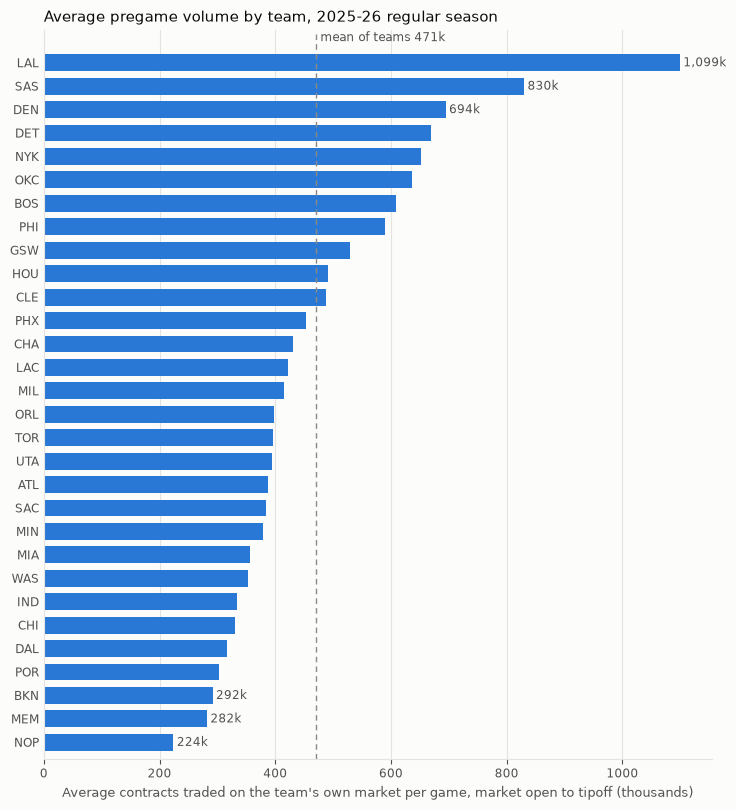

In [3]:
fig = team_volume_figure(tv, RESULTS_DIR / "eda_team_pregame_volume.png")

The Lakers are the most traded team, at about 1.10 million contracts per game on their own market. The Pelicans are the least traded, at about 224 thousand, roughly one fifth of the Lakers' figure. The average across the 30 teams is about 471 thousand, and 11 teams are above it.

Every team's median is below its mean, so each team has some games with much more volume than its typical game.

GSW and MIN have 81 games instead of 82. Their postponed game against each other is outside the main sample.

## 2. Example price path

One game, to show what the raw data looks like. The game is chosen by a fixed rule: among games with above-median pregame volume, the one whose `p_home` moved the most between the 24h snapshot and tipoff.

The minute-by-minute quotes and volume of that game are saved in `data/processed/example_price_path.csv`. `python src/export_price_path.py` builds that file from the raw cache, and `--event <ticker>` exports a different game.

Game in the file: KXNBAGAME-26APR12ATLMIA, 3,600 rows. The rule picks: KXNBAGAME-26APR12ATLMIA


{'event': 'KXNBAGAME-26APR12ATLMIA',
 'window_contracts': 1525011.0,
 'p_home_24h': 0.4504950495049505,
 'p_home_6h': 0.6485148514851485,
 'p_home_1h': 0.785,
 'p_home_0h': 0.7871287128712872}

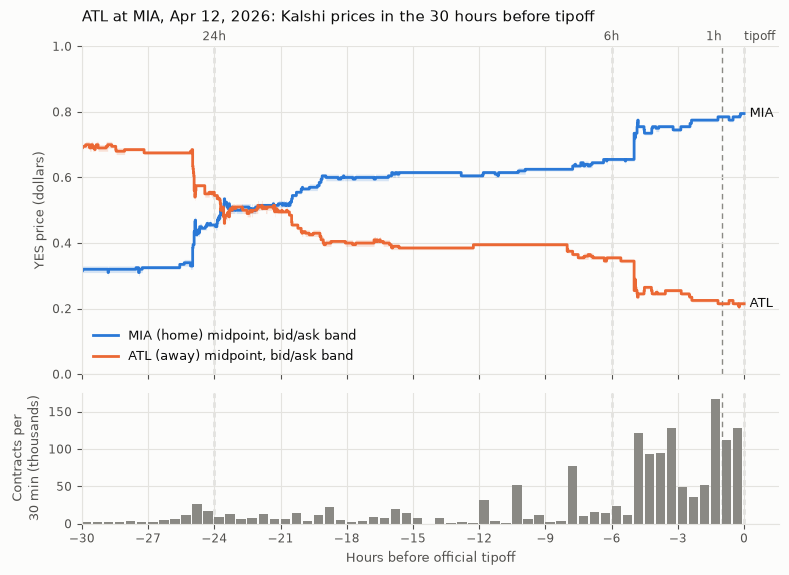

In [4]:
pp = read_csv(PRICE_PATH_CSV)
print(f"Game in the file: {pp['event_ticker'].iloc[0]}, {len(pp):,} rows. "
      f"The rule picks: {pick_example(sn)}")
fig, info = price_path_figure(pp, sn, RESULTS_DIR / "eda_price_path.png")
info

The rule picks Atlanta at Miami on April 12, 2026. The home price `p_home` was 0.450 at 24 hours before tipoff, 0.649 at 6 hours, 0.785 at 1 hour and 0.787 at tipoff. About 1.53 million contracts traded on the two markets in the 30-hour window.

The upper panel shows each market's bid/ask midpoint as a line, with the bid/ask band shaded around it. The dashed vertical lines are the four snapshot times. The lower panel shows contracts traded per 30 minutes on both markets together.

This game was picked because its price moved a lot. It is not a typical game.

## 3. Distribution of the tipoff price

The price used in the calibration tests is `p_home` at tipoff: the home team's normalized price, home / (home + away). This section shows how those 1,229 prices are spread.

In [5]:
p = tipoff_prices(sn)
summary = price_summary(p)
write_csv(summary, RESULTS_DIR / "eda_price_summary.csv")
display(summary.round(4))

,n,mean,sd,min,p10,p25,median,p75,p90,max,share_above_half
0,1229,0.5501,0.2259,0.035,0.225,0.3812,0.565,0.735,0.845,0.975,0.5793


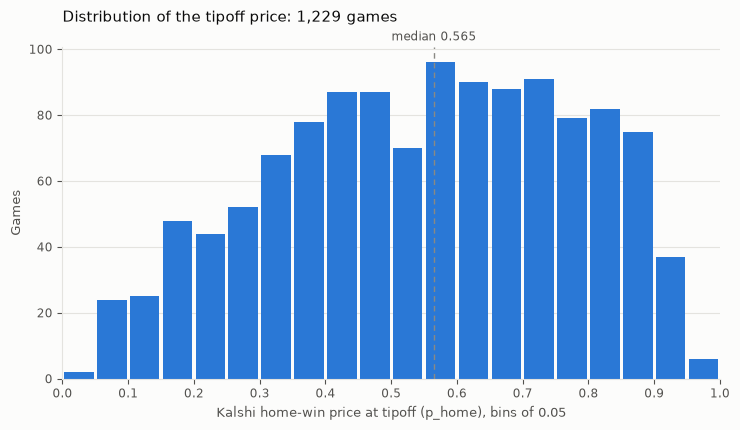

In [6]:
hist = price_histogram(p)
write_csv(hist, RESULTS_DIR / "eda_price_distribution.csv")
fig = price_distribution_figure(p, RESULTS_DIR / "eda_price_distribution.png")

The tipoff price runs from 0.035 to 0.975. Its mean is 0.550 and its median is 0.565. The home team is priced above 0.5 in 57.9% of games.

The middle half of the games is priced between 0.381 and 0.735. Prices near the ends are rare: 26 games are below 0.10 and 43 games are at 0.90 or above.

These numbers describe prices only. Whether a price of 0.70 means the home team wins about 70% of the time is the question of notebook 02.